# ECE 5831 – Assignment 06: Numerical Gradient
**Naveen Arul** · Fall 2026

A `TwoLayerNet` (Affine → Sigmoid → Affine → Softmax, cross-entropy loss) is trained with **numerical gradients**
(central difference, `h = 1e-4`) on the **Iris** and **MNIST** datasets, saved as pickle files, then reloaded and evaluated on the test sets.

| File | Purpose |
|---|---|
| `two_layer_net.py` | `TwoLayerNet` class (predict, loss, accuracy, numerical_gradient) |
| `datasets.py` | Loads Iris (`dataset/iris/*.csv`) and MNIST (`dataset/mnist/*.gz`) |
| `train.py` | Mini-batch training loop → `arul_<dataset>_nn_model.pkl` |
| `test.py` | Loads the pickle and reports actual / predicted / correct for test samples |

Training loop (Lecture 7): **init weights → random mini-batch → numerical slope → update weights → repeat**.

In [1]:
import json, inspect
import numpy as np
import matplotlib.pyplot as plt
import datasets
from two_layer_net import TwoLayerNet
print(inspect.getsource(TwoLayerNet))

class TwoLayerNet:
    def __init__(self, input_size, hidden_size, output_size, weight_init_std=0.01):
        self.params = {}
        self.params["w1"] = weight_init_std * np.random.randn(input_size, hidden_size)
        self.params["b1"] = np.zeros(hidden_size)
        self.params["w2"] = weight_init_std * np.random.randn(hidden_size, output_size)
        self.params["b2"] = np.zeros(output_size)

        # Extra information saved together with the model (filled in by train.py)
        self.class_names = None   # e.g. ['setosa', 'versicolor', 'virginica']
        self.x_mean = None        # feature normalisation used during training
        self.x_std = None

    # ---------------- activation functions ----------------
    def sigmoid(self, s):
        s = np.clip(s, -500, 500)  # avoid overflow warnings in np.exp
        return 1 / (1 + np.exp(-s))

    def softmax(self, s):
        if s.ndim == 1:  # single sample (batch size = 1)
            s = s - np.max(s)
            exp_s = 

### Sanity check of the numerical gradient
For a single softmax/cross-entropy output layer the exact gradient w.r.t. `b2` is `mean(y_hat − t)`. The numerical gradient should match it.

In [2]:
np.random.seed(0)
net = TwoLayerNet(4, 5, 3, weight_init_std=0.5)
x = np.random.randn(8, 4); t = datasets.one_hot(np.random.randint(0, 3, 8), 3)
num = net.numerical_gradient(x, t)["b2"]
exact = (net.predict(x) - t).mean(axis=0)
print("numerical:", num); print("exact    :", exact); print("max abs diff:", np.abs(num - exact).max())

numerical: [-0.07365594  0.0648653   0.00879064]
exact    : [-0.073656   0.0648653  0.0087907]
max abs diff: 6.353224761557197e-08


## Part 1 – Iris
### Dataset
150 samples, 4 features, 3 species. Stratified 80/20 split → 120 training samples (40/class) and 30 test samples (10/class), stored as CSV in `dataset/iris/`.

In [3]:
x_tr, y_tr = datasets.load("iris", "train"); x_te, y_te = datasets.load("iris", "test")
print("train:", x_tr.shape, "per class", np.bincount(y_tr)); print("test :", x_te.shape, "per class", np.bincount(y_te))
print(open("dataset/iris/iris_train.csv").read().splitlines()[:6])

train: (120, 4) per class [40 40 40]
test : (30, 4) per class [10 10 10]
['sepal_length,sepal_width,petal_length,petal_width,label,species', '4.4,2.9,1.4,0.2,0,setosa', '4.9,2.5,4.5,1.7,2,virginica', '6.8,2.8,4.8,1.4,1,versicolor', '4.9,3.1,1.5,0.1,0,setosa', '5.5,2.5,4.0,1.3,1,versicolor']


### Train
Hidden layer = 10 sigmoid units (83 parameters), lr = 0.5, batch = 20, 1000 iterations. Features are standardised with training-set mean/std (stored inside the model).

In [4]:
!python train.py --dataset iris

[iris] train=120 val=0 params=83 config={'hidden_size': 10, 'lr': 0.5, 'iters': 1000, 'batch_size': 20, 'weight_init_std': 0.1, 'log_every': 50, 'val_size': 0}
iter     1/1000  loss=1.0810  train_acc=0.3333  (0s)
iter    50/1000  loss=0.2796  train_acc=0.8250  (0s)
iter   100/1000  loss=0.2594  train_acc=0.9417  (1s)
iter   150/1000  loss=0.1616  train_acc=0.9583  (1s)
iter   200/1000  loss=0.1989  train_acc=0.9583  (1s)
iter   250/1000  loss=0.1389  train_acc=0.9667  (2s)
iter   300/1000  loss=0.0500  train_acc=0.9750  (2s)
iter   350/1000  loss=0.0787  train_acc=0.9750  (3s)
iter   400/1000  loss=0.0523  train_acc=0.9750  (3s)
iter   450/1000  loss=0.0403  train_acc=0.9750  (3s)
iter   500/1000  loss=0.0459  train_acc=0.9750  (4s)
iter   550/1000  loss=0.0346  train_acc=0.9750  (4s)
iter   600/1000  loss=0.0446  train_acc=0.9750  (4s)
iter   650/1000  loss=0.0533  train_acc=0.9833  (5s)
iter   700/1000  loss=0.0546  train_acc=0.9750  (5s)
iter   750/1000  loss=0.0127  train_acc=0.975

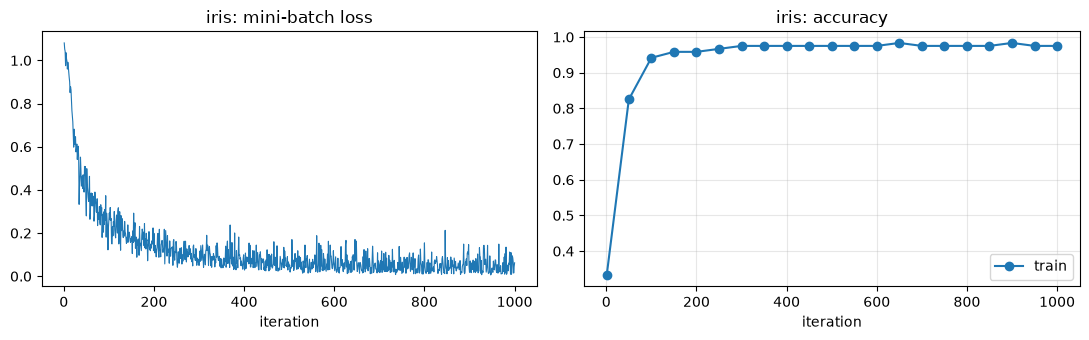

In [5]:
def plot_history(name):
    h = json.load(open(f"arul_{name}_train_history.json"))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h["iter"], h["loss"], lw=0.8); ax[0].set_title(f"{name}: mini-batch loss"); ax[0].set_xlabel("iteration")
    ax[1].plot(h["log_iter"], h["train_acc"], "o-", label="train")
    if h["val_acc"][0] is not None: ax[1].plot(h["log_iter"], h["val_acc"], "s-", label="validation")
    ax[1].set_title(f"{name}: accuracy"); ax[1].set_xlabel("iteration"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()
plot_history("iris")

### Test
Load `arul_iris_nn_model.pkl` and evaluate every Iris test sample (10 per class).

In [6]:
!python test.py --dataset iris

Model: arul_iris_nn_model.pkl
sample |     actual |  predicted | result
----------------------------------------------
     0 |     setosa |     setosa | correct
     1 |  virginica |  virginica | correct
     2 | versicolor | versicolor | correct
     3 | versicolor | versicolor | correct
     4 |     setosa |     setosa | correct
     5 | versicolor | versicolor | correct
     6 |     setosa |     setosa | correct
     7 |     setosa |     setosa | correct
     8 |  virginica |  virginica | correct
     9 | versicolor | versicolor | correct
    10 |  virginica |  virginica | correct
    11 |  virginica |  virginica | correct
    12 |  virginica |  virginica | correct
    13 | versicolor | versicolor | correct
    14 |     setosa |     setosa | correct
    15 |     setosa |     setosa | correct
    16 |     setosa |     setosa | correct
    17 | versicolor | versicolor | correct
    18 | versicolor | versicolor | correct
    19 |  virginica |  virginica | correct
    20 |     setosa |

## Part 2 – MNIST
### Dataset
60,000 training / 10,000 test images (28×28, flattened to 784 values in [0, 1]). 5,000 training images are held out for validation.

train: (60000, 784)  test: (10000, 784)


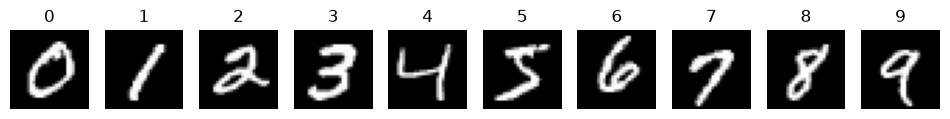

In [7]:
x_tr, y_tr = datasets.load("mnist", "train"); x_te, y_te = datasets.load("mnist", "test")
print("train:", x_tr.shape, " test:", x_te.shape)
fig, ax = plt.subplots(1, 10, figsize=(12, 1.6))
for c in range(10):
    ax[c].imshow(x_tr[np.where(y_tr == c)[0][0]].reshape(28, 28), cmap="gray"); ax[c].set_title(c); ax[c].axis("off")
plt.show()

### Train
A numerical gradient needs **two forward passes per parameter**. With 784 inputs the network has 784·H + H + 10·H + 10 parameters, so the hidden layer is kept at **10 units (7,960 parameters → 15,920 forward passes per update, ≈2.5 s per iteration)**.
lr = 1.0, batch = 100, 800 iterations.

In [8]:
!python train.py --dataset mnist

[mnist] train=55000 val=5000 params=7960 config={'hidden_size': 10, 'lr': 1.0, 'iters': 800, 'batch_size': 100, 'weight_init_std': 0.1, 'log_every': 50, 'val_size': 5000}
iter     1/800  loss=2.2749  train_acc=0.1017  val_acc=0.0882  (3s)
iter    50/800  loss=1.0730  train_acc=0.7109  val_acc=0.7114  (148s)
iter   100/800  loss=0.5501  train_acc=0.8484  val_acc=0.8484  (291s)
iter   150/800  loss=0.4689  train_acc=0.8731  val_acc=0.8686  (470s)
iter   200/800  loss=0.3283  train_acc=0.8857  val_acc=0.8778  (619s)
iter   250/800  loss=0.3329  train_acc=0.8971  val_acc=0.8880  (786s)
iter   300/800  loss=0.2569  train_acc=0.8943  val_acc=0.8934  (976s)
iter   350/800  loss=0.3234  train_acc=0.9052  val_acc=0.8988  (1299s)
iter   400/800  loss=0.3266  train_acc=0.9098  val_acc=0.9012  (1387s)
iter   450/800  loss=0.2695  train_acc=0.9061  val_acc=0.8952  (1481s)
iter   500/800  loss=0.2087  train_acc=0.9086  val_acc=0.8998  (2008s)
iter   550/800  loss=0.3508  train_acc=0.9163  val_acc=0.

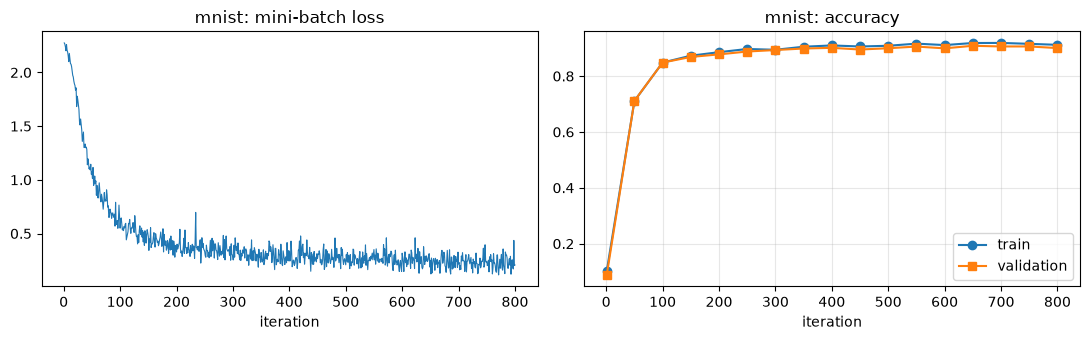

In [9]:
plot_history("mnist")

### Test
Load `arul_mnist_nn_model.pkl`, list 5 test samples per class (50 samples) and report accuracy on all 10,000 test images.

In [10]:
!python test.py --dataset mnist --per_class 5

Model: arul_mnist_nn_model.pkl
sample |     actual |  predicted | result
----------------------------------------------
     3 |          0 |          0 | correct
    10 |          0 |          0 | correct
    13 |          0 |          0 | correct
    25 |          0 |          0 | correct
    28 |          0 |          0 | correct
     2 |          1 |          1 | correct
     5 |          1 |          1 | correct
    14 |          1 |          1 | correct
    29 |          1 |          1 | correct
    31 |          1 |          1 | correct
     1 |          2 |          2 | correct
    35 |          2 |          2 | correct
    38 |          2 |          3 | incorrect
    43 |          2 |          2 | correct
    47 |          2 |          2 | correct
    18 |          3 |          3 | correct
    30 |          3 |          3 | correct
    32 |          3 |          3 | correct
    44 |          3 |          3 | correct
    51 |          3 |          3 | correct
     4 |          

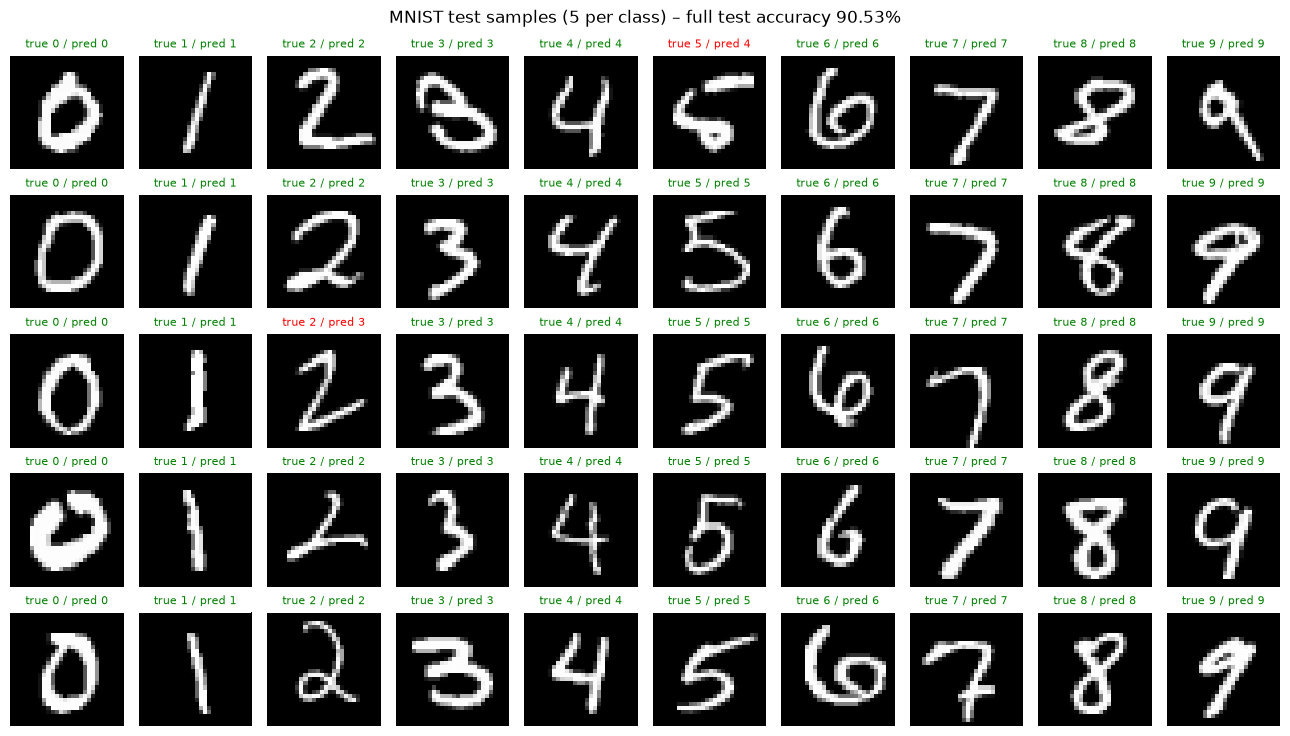

In [13]:
import importlib.util, os
_spec = importlib.util.spec_from_file_location("nn_test", os.path.join(os.getcwd(), "test.py"))
tester = importlib.util.module_from_spec(_spec); _spec.loader.exec_module(tester)
res = tester.evaluate("mnist", per_class=5, verbose=False)
fig, axes = plt.subplots(5, 10, figsize=(13, 7.5))
for k, (idx, actual, pred, result) in enumerate(res["rows"]):
    ax = axes[k % 5, k // 5]
    ax.imshow(res["x"][idx].reshape(28, 28), cmap="gray"); ax.axis("off")
    ax.set_title(f"true {actual} / pred {pred}", fontsize=8, color="green" if result == "correct" else "red")
plt.suptitle(f"MNIST test samples (5 per class) – full test accuracy {res['accuracy']:.2%}"); plt.tight_layout(); plt.show()

## Summary

In [14]:
import pickle, os
for name in ["iris", "mnist"]:
    r = tester.evaluate(name, verbose=False)
    print(f"{name:5s}: model file {tester.model_path(name)} ({os.path.getsize(tester.model_path(name))/1024:.1f} KB)  test accuracy = {r['accuracy']:.4f}")

iris : model file arul_iris_nn_model.pkl (1.1 KB)  test accuracy = 0.9667
mnist: model file arul_mnist_nn_model.pkl (62.6 KB)  test accuracy = 0.9053


Both networks are trained purely with numerical gradients. Iris converges in seconds because the model has only 83 parameters.
MNIST is far more expensive (≈16k forward passes per update), which is why the hidden layer is small; backpropagation would compute the same gradients in a single backward pass and allow a much larger network.